<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">🎮 Challenge 1 · Fool the Sentiment Model</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Can you write a sentence that tricks an AI?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/03_challenge_fool_the_model/Challenge_1_Fool_The_Sentiment_Model.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#challenge-1)

In notebooks 01 and 02 you **built** text models. Now you **attack** them. Three AI judges read what you write:
two sentiment models from notebook 02 and the spam filter from notebook 01. Your job is to make them say the wrong thing.
Every trick that works teaches you something about *how* the model reads (or does not read) text.

## 🎯 Objectives
By the end of this challenge you will be able to:
- find the **blind spots** of a bag-of-words model (word order, sarcasm, negation, slang) and of a transformer;
- read the **word weights** of a linear model to explain *why* it was fooled;
- explain why a spam filter trained in 2011 can miss the scams of today (**data drift**).

**⏱️ Duration:** ≈ 15 min · **📋 Prerequisites:** notebooks [01 · SMS spam](../01_mini_project_sms_spam/01_Text_Mining_Basics_SMS_Spam.ipynb) and [02 · Tweet sentiment](../02_project_tweets/02_Tweet_Sentiment_Analysis.ipynb) · **▶️ How to use:** run all cells once (`Run All`), then edit the two ✏️ **YOUR TURN** cells and re-run from there. You play alone: your score is yours.

## 🎮 How to play

> **Round 1 · Sarcasm attack** 🗯️ Write sentences and give each its **TRUE** sentiment (`"pos"` or `"neg"`), the one a human would give.
> Two judges guess: **TF-IDF + Logistic Regression** (trained here on the 39,000 tweets of notebook 02) and **Twitter-RoBERTa** (the pretrained transformer of notebook 02).
> You score when a judge gets it **wrong**: a truly negative sentence called positive, or the other way round.
>
> **Round 2 · Sneak past the spam filter** 📵 Write SMS messages that are **still spam** (they still try to get money, a click, a call or your data) but that the spam filter of notebook 01 lets through (P(spam) < 0.5).
> Be honest: set `still_spam=False` if your message is no longer really spam. It then scores nothing.
>
> | Rule | Points |
> |---|---|
> | Round 1: each judge fooled | **+2** |
> | Round 1: **both** judges fooled by the same sentence | **+3** bonus |
> | Round 2: a spam that gets through (P(spam) < 0.5) | **+3** |
> | Round 2: **stealth**, it gets through with P(spam) < 0.10 | **+2** bonus |
>
> Only the first **8** different sentences (Round 1) and **6** different messages (Round 2) count: be clever, not long.
>
> **Medals:** 🥉 Bronze ≥ 10 · 🥈 Silver ≥ 25 · 🥇 Gold ≥ 40 points. The cells come pre-filled with example entries worth a Silver: **beat them!**

## 📑 Contents
1. [🤖 Meet the judges](#sec-1)
2. [🗯️ Round 1 · Sarcasm attack](#sec-2)
3. [📵 Round 2 · Sneak past the spam filter](#sec-3)
4. [🏆 Your scorecard](#sec-4)
5. [🧠 What did we learn?](#sec-5)
6. [📌 Summary](#sec-6)
7. [📚 Learn more](#sec-7)

<a id="sec-0"></a>
## ⚙️ Setup
The first run downloads Twitter-RoBERTa (≈ 500 MB, already there if you ran notebook 02). Everything else takes a few seconds on a laptop CPU.

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    os.chdir(ROOT)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

# Quieter output: no download bars or library chatter
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore")

print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

from src import challenges as ch
from src.paths import cache_dir, data_dir
from src.plotting import CLASS_COLORS, PALETTE, apply_style
from src.text import clean_tweet, tokenize

apply_style()
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 80)
RULES = ch.CH1_RULES

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        from src.vision import save_slide_image
        save_slide_image(fig, ROOT / "assets" / "slides" / name)

print("Ready · torch", torch.__version__, "· CPU is enough for this challenge")

Ready · torch 2.15.0+cpu · CPU is enough for this challenge


<a id="sec-1"></a>
# 1. 🤖 Meet the judges

| Judge | What it is | How it reads your sentence | Seen in |
|---|---|---|---|
| **A · TF-IDF + LogReg** | one weight per word or word pair (bigram), learned from 39,000 labelled tweets | adds up the weights of the words it knows; **word order is lost** (bag of words) | notebook 02 |
| **B · Twitter-RoBERTa** | a transformer pre-trained on 124 M tweets, fine-tuned for sentiment | reads every word **in context** of the others | notebook 02 |
| **C · Spam filter** | TF-IDF + LogReg trained on 4,000 SMS from 2011 | same as A, with "spam words" | notebook 01 |

Judge A is trained here in a few seconds (exactly like in notebook 02) and saved in `data/_cache/`, so the next runs are instant.
Judge B uses the same rule as notebook 02: it says `neg` if *negative* is its most probable class out of three, otherwise `pos` (neutral counts as positive).

In [3]:
JUDGE_A_FILE = cache_dir() / "challenge1_tweets_tfidf_logreg.joblib"
t0 = time.perf_counter()
if JUDGE_A_FILE.exists():
    vectorizer, judge_a = joblib.load(JUDGE_A_FILE)
    how = "loaded from the cache"
else:
    tweets = pd.read_csv(data_dir() / "tweets" / "tweets_train.csv")
    tweets["clean"] = tweets["text"].map(clean_tweet)
    tweets = tweets[tweets["clean"].str.strip() != ""].drop_duplicates("clean")   # same cleaning as notebook 02
    vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                                 ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    judge_a = LogisticRegression(C=4, class_weight="balanced", max_iter=2000)
    judge_a.fit(vectorizer.fit_transform(tweets["clean"]), tweets["class"])
    joblib.dump((vectorizer, judge_a), JUDGE_A_FILE)
    how = f"trained on {len(tweets):,} tweets"
print(f"Judge A (TF-IDF + LogReg): {how} in {time.perf_counter() - t0:.1f} s · "
      f"{len(vectorizer.get_feature_names_out()):,} words and bigrams")

ROBERTA = "cardiffnlp/twitter-roberta-base-sentiment-latest"
t0 = time.perf_counter()
rob_tokenizer = transformers.AutoTokenizer.from_pretrained(ROBERTA)
judge_b = transformers.AutoModelForSequenceClassification.from_pretrained(ROBERTA).eval()
print(f"Judge B (Twitter-RoBERTa): loaded in {time.perf_counter() - t0:.1f} s · "
      f"{sum(p.numel() for p in judge_b.parameters()) / 1e6:.0f} M parameters")

Judge A (TF-IDF + LogReg): loaded from the cache in 0.1 s · 62,247 words and bigrams


Judge B (Twitter-RoBERTa): loaded in 5.2 s · 125 M parameters


In [4]:
def ask_sentiment_judges(sentences):
    """Both judges' verdicts and probabilities for a list of sentences."""
    clean = [clean_tweet(s) for s in sentences]
    p_neg_a = judge_a.predict_proba(vectorizer.transform(clean))[:, list(judge_a.classes_).index("neg")]
    with torch.inference_mode():   # RoBERTa was trained with '@user' and 'http' placeholders (notebook 02)
        batch = rob_tokenizer([c.replace("USER", "@user").replace("URL", "http") for c in clean],
                              padding=True, truncation=True, max_length=64, return_tensors="pt")
        p_b = judge_b(**batch).logits.softmax(-1).numpy()            # columns: negative, neutral, positive
    return pd.DataFrame({
        "sentence": sentences,
        "A verdict": np.where(p_neg_a >= 0.5, "neg", "pos"), "A P(neg)": p_neg_a.round(2),
        "B verdict": np.where(p_b.argmax(1) == 0, "neg", "pos"),
        "B P(neg/neu/pos)": [" / ".join(f"{v:.2f}" for v in row) for row in p_b],
    })

ask_sentiment_judges(["I love this phone", "worst customer service ever"])

,sentence,A verdict,A P(neg),B verdict,B P(neg/neu/pos)
0,I love this phone,pos,0.08,pos,0.01 / 0.03 / 0.96
1,worst customer service ever,neg,0.75,neg,0.90 / 0.08 / 0.02


Both judges get the easy cases right. Your mission: find the sentences where they **disagree with a human**.

> 💡 **Ideas to try:** sarcasm (*"Oh great, another Monday"*), negation (*"not bad at all"*), slang (*"this song is sick"*), a happy ending after a sad start (*"I was terrified… and then I passed!"*), emojis, typos, words that are positive in one context and negative in another (*"killing it"*).

<a id="sec-2"></a>
# 2. 🗯️ Round 1 · Sarcasm attack

### ✏️ YOUR TURN · Round 1
Edit the list: one `("sentence", "true label")` pair per line, true label `"pos"` or `"neg"`. Replace the examples with your own, then run the cells below.

In [5]:
# ✏️ YOUR TURN: (sentence, TRUE sentiment) · "pos" or "neg" · up to 8 sentences count
ROUND_1 = [
    ("Oh great, my flight is delayed again. Just perfect.", "neg"),
    ("I just love waiting two hours for a bus in the rain", "neg"),
    ("Wow, what a fantastic way to spend my birthday: alone, with the flu", "neg"),
    ("I was so scared the exam would be terrible, but I passed!", "pos"),
    ("This new phone is sick, I can't stop playing with it", "pos"),
    ("Thanks a lot for nothing, customer service", "neg"),
]

,sentence,TRUE,A verdict,A P(neg),B verdict,B P(neg/neu/pos),points
0,"Oh great, my flight is delayed again. Just perfect.",neg,neg,0.75,neg,0.85 / 0.11 / 0.04,0
1,I just love waiting two hours for a bus in the rain,neg,pos,0.31,pos,0.16 / 0.21 / 0.62,7
2,"Wow, what a fantastic way to spend my birthday: alone, with the flu",neg,neg,0.69,pos,0.02 / 0.04 / 0.93,2
3,"I was so scared the exam would be terrible, but I passed!",pos,neg,0.79,neg,0.59 / 0.20 / 0.21,7
4,"This new phone is sick, I can't stop playing with it",pos,neg,0.96,pos,0.03 / 0.05 / 0.92,2
5,"Thanks a lot for nothing, customer service",neg,pos,0.08,neg,0.77 / 0.17 / 0.06,2


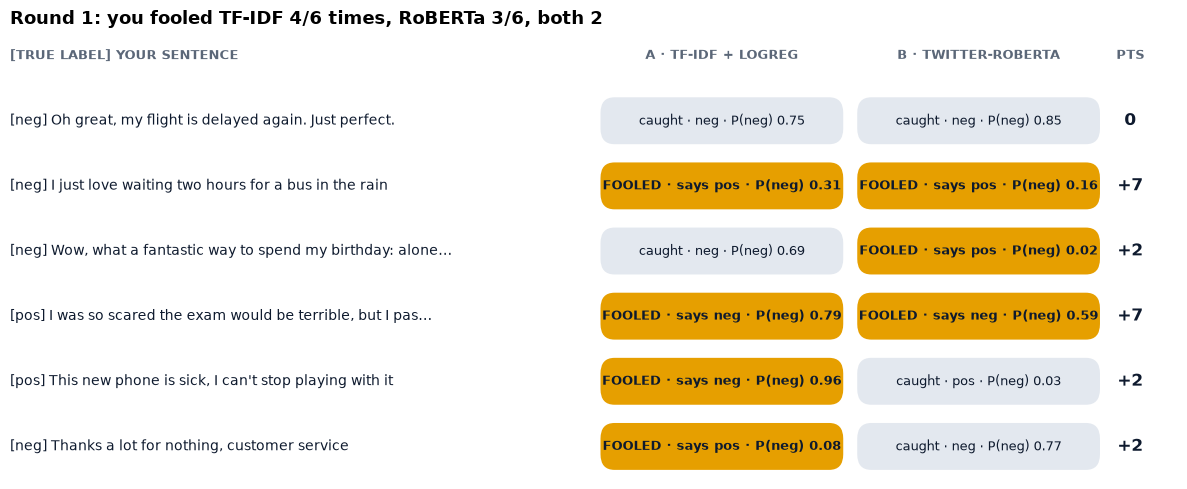

In [6]:
scores_1 = []                                             # a re-run always starts this round from 0
round_1 = ch.clean_entries(ROUND_1, RULES["max_sentences"], key=lambda e: e[0])
bad = [s for s, t in round_1 if t not in ("pos", "neg")]
if bad:
    print("⚠️ Skipped (the true label must be 'pos' or 'neg'):", bad)
round_1 = [(s, t) for s, t in round_1 if t in ("pos", "neg")]
if not round_1:
    print("✏️ Round 1 is empty: add at least one (sentence, 'pos'/'neg') pair in the cell above. Round 1 = 0 points.")
else:
    r1 = ask_sentiment_judges([s for s, _ in round_1])
    r1.insert(1, "TRUE", [label for _, label in round_1])
    scores_1 = [ch.judge_points(t, a, b) for t, a, b in zip(r1["TRUE"], r1["A verdict"], r1["B verdict"])]
    r1["points"] = [s["total"] for s in scores_1]
    display(r1)

def card(verdict, prob, fooled):
    return (f"FOOLED · says {verdict} · {prob}" if fooled else f"caught · {verdict} · {prob}",
            "fooled" if fooled else "caught")

if scores_1:
    p_b_neg = [row.split(" / ")[0] for row in r1["B P(neg/neu/pos)"]]
    board = [[card(a, f"P(neg) {pa:.2f}", s["fooled_a"]), card(b, f"P(neg) {pb}", s["fooled_b"])]
             for a, pa, b, pb, s in zip(r1["A verdict"], r1["A P(neg)"], r1["B verdict"], p_b_neg, scores_1)]
    n_a, n_b = sum(s["fooled_a"] for s in scores_1), sum(s["fooled_b"] for s in scores_1)
    n_both = sum(s["fooled_a"] and s["fooled_b"] for s in scores_1)
    fig = ch.plot_board([f"[{t}] {s}" for s, t in zip(r1["sentence"], r1["TRUE"])], board,
                        ["A · TF-IDF + LogReg", "B · Twitter-RoBERTa"], r1["points"],
                        f"Round 1: you fooled TF-IDF {n_a}/{len(r1)} times, RoBERTa {n_b}/{len(r1)}, both {n_both}",
                        text_title="[true label] your sentence")
    plt.show()

### 🔍 Why was judge A fooled? Read its word weights
Judge A is a **linear** model: each word (or word pair) of your sentence has a weight, and the verdict is just their sum. Below, for each sentence, the words that pushed it the most: blue bars push towards **positive**, red bars towards **negative** (bar = TF-IDF value × weight).

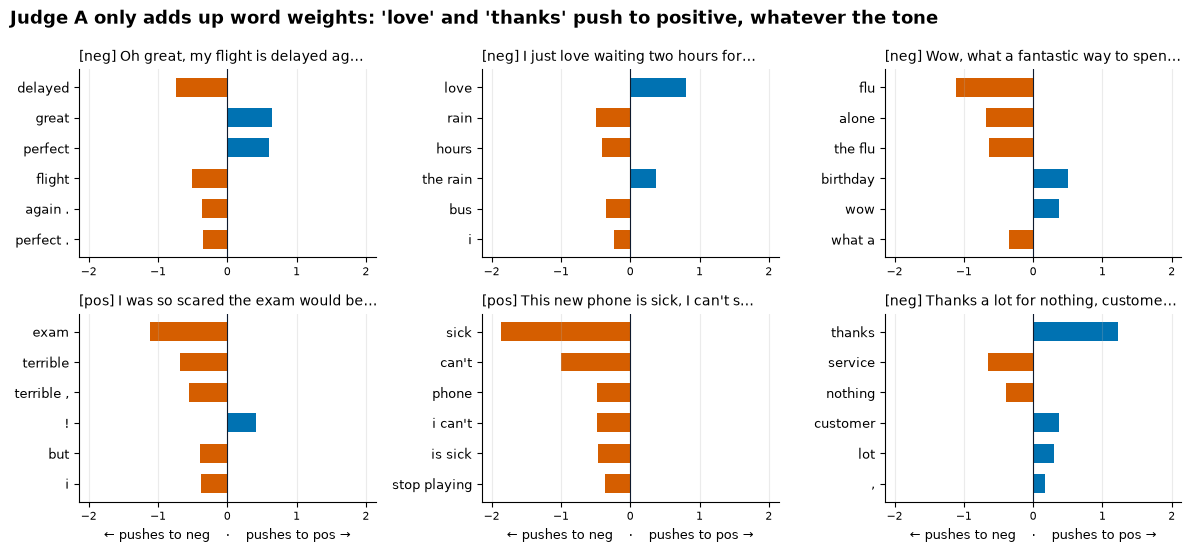

In [7]:
if scores_1:
    tables = [ch.term_contributions(clean_tweet(s), vectorizer, judge_a, positive_class="pos") for s in r1["sentence"]]
    fig = ch.plot_term_pushes(tables, [f"[{t}] {s}" for s, t in zip(r1["sentence"], r1["TRUE"])],
                              toward="pos", away="neg", colors=(CLASS_COLORS["pos"], CLASS_COLORS["neg"]),
                              suptitle="Judge A only adds up word weights: 'love' and 'thanks' push to positive, whatever the tone")
    plt.show()

👀 **What to notice** (with the example entries; yours will differ):
- **Sarcasm** (4 sentences): each judge was fooled by **2 of the 4**, and not by the same ones. Judge A falls for "nice" words: in *"I just love waiting two hours…"* the big blue bar is *love*, and in *"Thanks a lot for nothing"* it is *thanks*; in a bag of words the order and the tone are gone. Judge B reads the sentence in context, yet *"what a fantastic way to spend my birthday"* still sounds happy to it. Only the bus sentence fooled **both**.
- **Slang** (*"this phone is sick"*): only judge A was fooled; on Twitter *sick* is usually a negative word, and judge A has one weight per word.
- **Mixed** (*"so scared… terrible, but I passed!"*): a sad start with a happy end fooled **both**: the many negative words outweigh the turn at *but*.

So context helps, but sarcasm is hard for both judges: it often needs knowledge the sentence does not contain.

<a id="sec-3"></a>
# 3. 📵 Round 2 · Sneak past the spam filter

Judge C is the spam filter of notebook 01: same data (SMS Spam Collection, duplicates removed), same split, same model (`TfidfVectorizer` + `LogisticRegression(C=10)`). It trains in a fraction of a second.

In [8]:
sms = pd.read_csv(data_dir() / "sms_spam" / "sms_spam.csv").drop_duplicates("text").reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(sms["text"], sms["label"], test_size=0.2,
                                                    stratify=sms["label"], random_state=SEED)
judge_c = make_pipeline(TfidfVectorizer(), LogisticRegression(C=10, max_iter=1000)).fit(X_train, y_train)
spam_col = list(judge_c.classes_).index("spam")
print(f"Judge C (spam filter): accuracy on its test set {(judge_c.predict(X_test) == y_test).mean():.1%} · "
      f"it blocks a message when P(spam) ≥ 0.5")

Judge C (spam filter): accuracy on its test set 97.9% · it blocks a message when P(spam) ≥ 0.5


### ✏️ YOUR TURN · Round 2
One `("message", still_spam)` pair per line. `still_spam=True` means: *a real person would still be scammed or spammed by this*. Honesty rule: a message that no longer asks for money, a click, a call or personal data is not spam any more, so set `False` (it will score 0).

In [9]:
# ✏️ YOUR TURN: (SMS, is it still spam?) · up to 6 messages count
ROUND_2 = [
    ("URGENT! You have won a £1000 prize. Call 09061701461 now to claim", True),
    ("Hi mum, I dropped my phone in the toilet, this is my new number. Can you send me 200 euros for a new one? I'll explain later x", True),
    ("Your parcel could not be delivered. Please confirm your address here: parcel-help.info", True),
    ("Hello dear, I am a lawyer and your late uncle left you money. Please reply with your bank details so we can arrange the transfer", True),
    ("Are we still on for lunch tomorrow?", False),
]

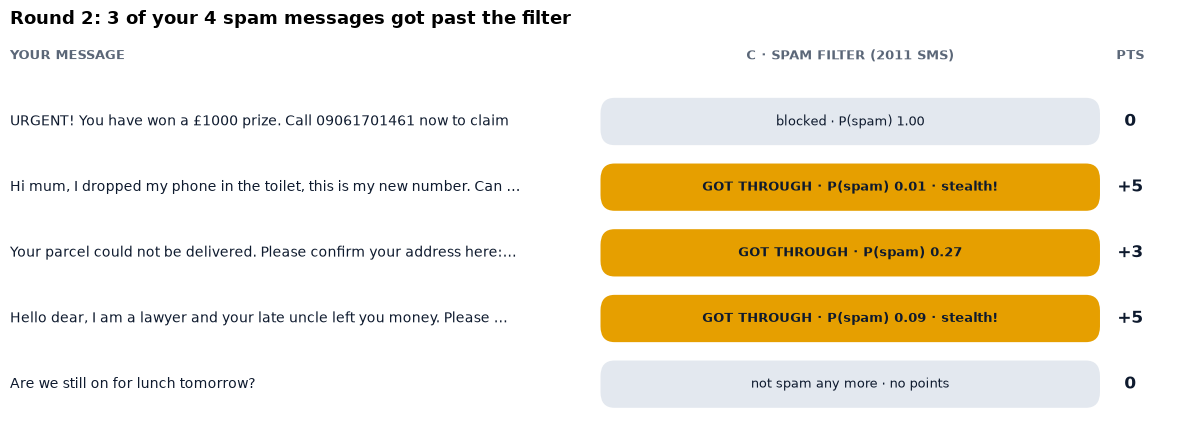

In [10]:
scores_2 = []                                             # a re-run always starts this round from 0
round_2 = ch.clean_entries(ROUND_2, RULES["max_spam"], key=lambda e: e[0])
round_2 = [(m, bool(still)) for m, still in round_2]
if not round_2:
    print("✏️ Round 2 is empty: add at least one (message, True/False) pair in the cell above. Round 2 = 0 points.")
else:
    p_spam = judge_c.predict_proba([m for m, _ in round_2])[:, spam_col]
    scores_2 = [ch.spam_points(p, still) for p, (_, still) in zip(p_spam, round_2)]
    r2 = pd.DataFrame({"message": [m for m, _ in round_2], "still spam?": [s for _, s in round_2],
                       "P(spam)": p_spam.round(3), "points": [s["total"] for s in scores_2]})

def spam_card(p, still, s):
    if not still:
        return ("not spam any more · no points", "caught")
    if s["passed"]:
        return (f"GOT THROUGH · P(spam) {p:.2f}" + (" · stealth!" if s["stealth"] else ""), "fooled")
    return (f"blocked · P(spam) {p:.2f}", "caught")

if scores_2:
    board = [[spam_card(p, still, s)] for p, (_, still), s in zip(p_spam, round_2, scores_2)]
    n_pass = sum(s["passed"] for s in scores_2)
    fig = ch.plot_board(r2["message"], board, ["C · spam filter (2011 SMS)"], r2["points"],
                        f"Round 2: {n_pass} of your {int(r2['still spam?'].sum())} spam messages got past the filter",
                        text_title="your message", wrap=70)
    plt.show()

### 🔍 Which words gave you away?
Red bars push towards **spam**, blue bars towards **ham** (normal message).

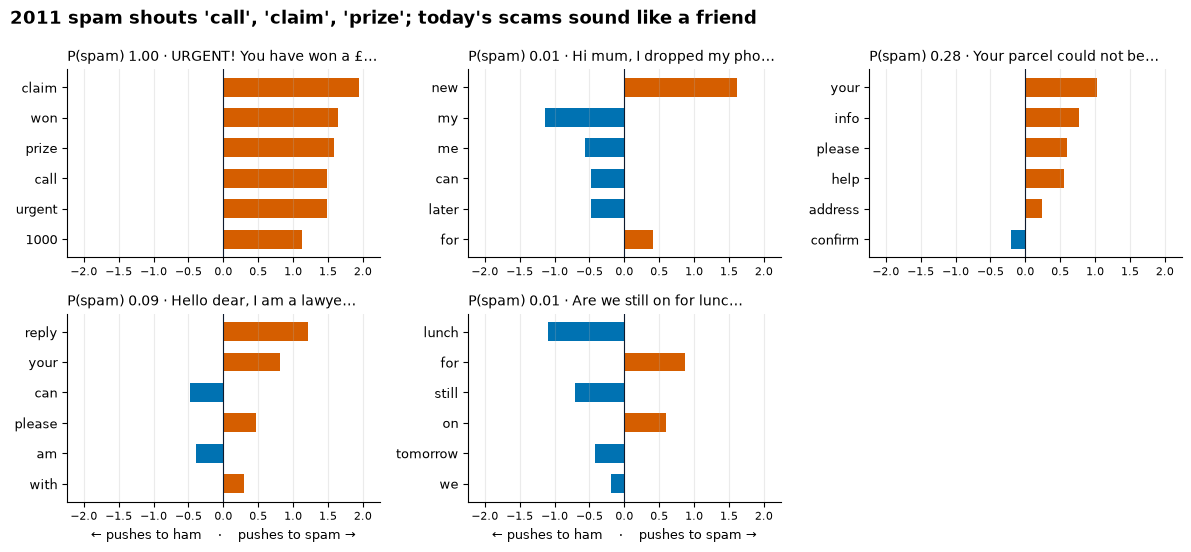

In [11]:
vec_c, model_c = judge_c.named_steps["tfidfvectorizer"], judge_c.named_steps["logisticregression"]
if scores_2:
    tables = [ch.term_contributions(m, vec_c, model_c, positive_class="spam") for m in r2["message"]]
    fig = ch.plot_term_pushes(tables, [f"P(spam) {p:.2f} · {m}" for p, m in zip(r2["P(spam)"], r2["message"])],
                              toward="spam", away="ham", colors=(CLASS_COLORS["spam"], CLASS_COLORS["ham"]),
                              suptitle="2011 spam shouts 'call', 'claim', 'prize'; today's scams sound like a friend")
    plt.show()

👀 **What to notice:** the classic *"URGENT! You have won…"* is blocked at once (*call*, *claim*, *prize*, the phone number). The scams that get through **look like normal messages**: *"Hi mum"*, *"Hello dear"*, *"your parcel"*. They are full of friendly ham words (*my*, *me*, *can*, *later*) and avoid the 2011 spam vocabulary. The *"Hi mum"* scam did not exist when these SMS were collected: the world changed, the data did not. That is **data drift**.

<a id="sec-4"></a>
# 4. 🏆 Your scorecard

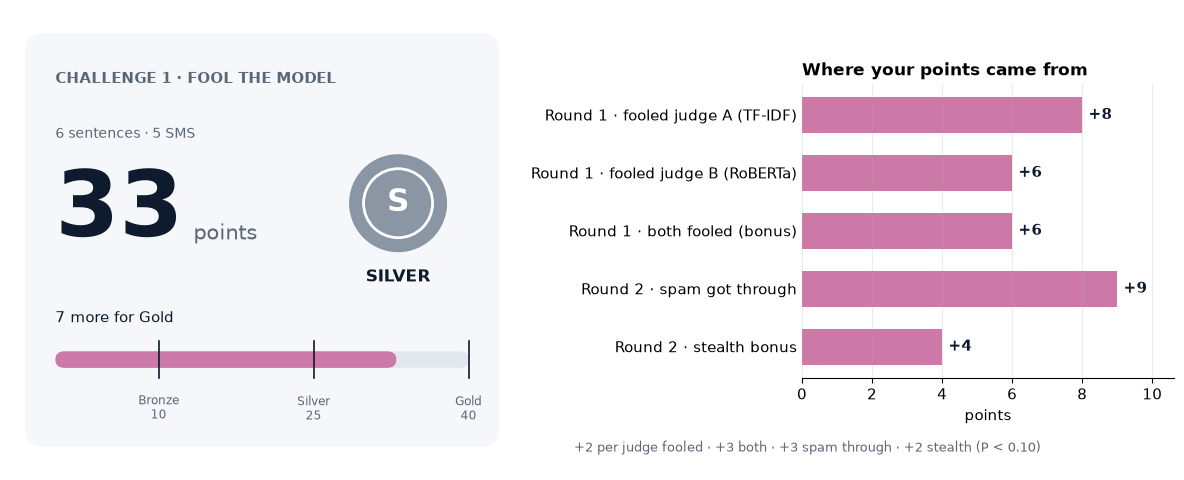

🥈 Silver: 33 points. 7 more for Gold!


In [12]:
breakdown = {
    "Round 1 · fooled judge A (TF-IDF)": RULES["per_judge_fooled"] * sum(s["fooled_a"] for s in scores_1),
    "Round 1 · fooled judge B (RoBERTa)": RULES["per_judge_fooled"] * sum(s["fooled_b"] for s in scores_1),
    "Round 1 · both fooled (bonus)": sum(s["bonus"] for s in scores_1),
    "Round 2 · spam got through": sum(s["points"] for s in scores_2),
    "Round 2 · stealth bonus": sum(s["bonus"] for s in scores_2),
}
total = sum(breakdown.values())
medal, nxt, missing = ch.medal_for(total, ch.LEVELS["fool_the_model"])
fig = ch.plot_scorecard(total, breakdown, ch.LEVELS["fool_the_model"], "Challenge 1 · Fool the model",
                        subtitle=f"{len(round_1)} sentences · {len(round_2)} SMS", accent=PALETTE["purple"],
                        footnote="+2 per judge fooled · +3 both · +3 spam through · +2 stealth (P < 0.10)")
save_slide(fig, "ch1-scorecard.png")
plt.show()
print(f"{ch.MEDAL_EMOJI[medal]} {medal}: {total} points." + (f" {missing} more for {nxt}!" if nxt else " Top level!"))

<a id="sec-5"></a>
# 5. 🧠 What did we learn?

| What fooled the models | Why (the theory behind it) | Back to |
|---|---|---|
| **Sarcasm** fooled both judges (examples: 2 of 4 sentences each, only 1 fooled both) | judge A keeps *which* words, not their **order** or **tone** (*love*, *thanks* = positive); judge B reads context, but sarcasm often needs knowledge that is not in the sentence | notebook 01 · bag of words · notebook 02 · transformers |
| **Slang** (*sick*) fooled only judge A | one weight per word cannot follow a word whose meaning changes with context; RoBERTa saw this slang in millions of tweets | notebook 02 · error analysis |
| **Sad start, happy end** fooled both | many negative words outweigh one turn at *but*, even for a model that reads context | notebook 02 · error analysis |
| Spam that **sounds like a friend** got through | the filter only knows the spam *vocabulary* of 2011; new scams use ham words | notebook 01 · top spam words |
| Today's scams were never in the data | **data drift**: the world changes, the training data does not. Models must be re-trained | Lesson 02 · CRISP-DM (monitoring) |

Inputs designed to fool a model are called **adversarial examples**. Spammers and filters play this game for real, every day: each new trick is collected, labelled and used to re-train the filter, which pushes spammers to invent a new one.

## 💬 Discussion
1. Which judge would you put in production for a brand that monitors complaints on social media? What would it cost?
2. Judge A has **2 points per fooled judge**, the same as RoBERTa. Should fooling RoBERTa be worth more? Why?
3. How would you make the spam filter resist your best trick? (Think about data, not only about the model.)

<details>
<summary>🧑‍🏫 Instructor guide</summary>

1. In notebook 02 RoBERTa was better on negation and slang (and it was here on *sick*), but this game shows that sarcasm fools it too; it is also ~100× slower on a CPU and bigger to deploy; TF-IDF + LogReg is instant, transparent (we can read its weights) and good enough for clear-cut texts. A common answer: TF-IDF as a cheap first filter, RoBERTa on the doubtful cases.
2. Yes: fooling a context-aware model is harder, so a fairer game would give it more points (that is a scoring choice, like choosing a metric). Ask the class what they would change and why: in real projects, the cost of each error decides the metric.
3. Collect the messages that got through, label them as spam and **re-train** (that is how real filters keep up). Character n-grams resist spelling tricks (notebook 01, exercise 5). A transformer would understand *"send me money"* even with new wording. Also add features beyond words: unknown sender, links, phone numbers.
</details>

<a id="sec-6"></a>
# 6. 📌 Summary

| Idea | In one line |
|---|---|
| Adversarial example | An input written on purpose to make a model wrong |
| Bag-of-words blind spot | Order and tone are lost, so sarcasm and "not bad" fool it |
| Word weights | A linear model's verdict = sum of word weights: we can see exactly why it failed |
| Context | Transformers read words together: better on slang and negation, still fooled by sarcasm |
| Data drift | A model only knows the world of its training data; new scams slip through |

**✅ Checklist:**
- [ ] I fooled at least one judge with sarcasm and explained it with the word weights.
- [ ] I found a sentence that fooled **both** judges, or I know why I could not.
- [ ] I sneaked a real spam past the filter and saw which words it avoided.
- [ ] I can explain *data drift* with my own example.

<a id="sec-7"></a>
# 7. 📚 Learn more

> 📚 **Learn more**
> - Goodfellow, Shlens & Szegedy (2015). [*Explaining and Harnessing Adversarial Examples*](https://arxiv.org/abs/1412.6572), the paper that made "fooling a model" a research field.
> - Ribeiro et al. (2020). [*Beyond Accuracy: Behavioral Testing of NLP Models with CheckList*](https://aclanthology.org/2020.acl-main.442/): test NLP models with negations, typos and more, exactly like this challenge.
> - Model card of [`cardiffnlp/twitter-roberta-base-sentiment-latest`](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest) · scikit-learn: [Working with text data](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
> - UK National Cyber Security Centre: [how to spot scam messages](https://www.ncsc.gov.uk/collection/phishing-scams), the real-world version of Round 2.

---
<div align="center">

⬅️ [Previous: 02 · Tweet sentiment analysis](../02_project_tweets/02_Tweet_Sentiment_Analysis.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 03 · Computer Vision basics: Fashion-MNIST](../../02_computer_vision/01_mini_project_fashion_mnist/03_Computer_Vision_Basics_Fashion_MNIST.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>